# Tokenizer Efficiency for Hong Kong Multilingual Text

**Research question.** How many tokens do popular tokenizers need to encode the *same meaning* in English, written Chinese (Traditional and Simplified), Cantonese, Cantonese–English code-mixed text and Python code, and how much information is lost when the text is decoded again? Is the cost different for Hong Kong text?

**Method in brief.**
1. **Main benchmark: FLORES-200 devtest** (via FLORES+): 1,012 professionally translated parallel sentences in English, Traditional Chinese, Simplified Chinese and Cantonese. Metrics are corpus-level, with bootstrap confidence intervals.
2. **Hong Kong case study: hand-written set** (`sentences.json`): five parallel sets (English, Traditional, Simplified, Cantonese, code-mixed) plus three Python snippets. It covers code-mixing, colloquial Cantonese and code, which FLORES lacks.
3. **Six tokenizers** (3 `tiktoken` encodings, 3 Hugging Face tokenizers). Only tokenizer files are downloaded, never model weights.
4. **Metrics:** token count, tokens per character, premium relative to English, unknown tokens and split-character fragments.
5. **Round-trip checks:** decode the token ids and compare with the original, exactly and after normalisation. A lower token count is only meaningful if the text can be reconstructed.
6. **Mitigation experiment:** does removing the spaces between Chinese and English in code-mixed text change the token count?
7. **Vocabulary extension demo:** adding the characters that mBERT maps to `[UNK]` to its vocabulary.

Results are written to `output/` as CSV tables, charts and HTML token-boundary views.

## 1. Setup and environment

Imports, output folder and package versions. The versions are also saved to `output/environment.txt` (together with the Hugging Face tokenizer revisions, see Section 4) so the run can be reproduced.

In [1]:
import os, warnings
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"                 # hides the "PyTorch was not found" notice
warnings.filterwarnings("ignore", message=".*IProgress.*")     # tqdm notebook-widget notice (prints local paths)
import sys, json, bisect, html, platform, re, unicodedata
from importlib import metadata
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import tiktoken, transformers, tokenizers, huggingface_hub
from transformers import AutoTokenizer
from huggingface_hub import hf_hub_download
from opencc import OpenCC
from IPython.display import HTML, display

OUT = Path("output"); OUT.mkdir(exist_ok=True)
env_lines = [f"Python: {platform.python_version()}", f"Platform: {platform.platform()}"]
for m in (tiktoken, transformers, tokenizers, huggingface_hub, pd, matplotlib):
    env_lines.append(f"{m.__name__.split('.')[0] if m is pd else m.__name__}: {m.__version__}")
env_lines.append("opencc-python-reimplemented: " + metadata.version("opencc-python-reimplemented"))
print("\n".join(env_lines))

Python: 3.10.11
Platform: Windows-10-10.0.19045-SP0
tiktoken: 0.14.0
transformers: 5.19.0
tokenizers: 0.23.3
huggingface_hub: 2.2.0
pandas: 2.3.3
matplotlib: 3.10.9
opencc-python-reimplemented: 0.1.7


## 2. Helper functions

Each tokenizer is wrapped in a small class with one method, `analyze(text)`. It returns one record per token: character span (`start`, `end`), whether the token is a **fragment** (invalid UTF-8 on its own), whether it is **unknown**, and its text. All metrics and the HTML view are computed from these records, so the two always agree.

In [2]:
def bytes_to_unicode():
    # GPT-2 byte <-> printable-character table, used by Qwen's byte-level BPE
    bs = list(range(33, 127)) + list(range(161, 173)) + list(range(174, 256))
    cs, n = bs[:], 0
    for b in range(256):
        if b not in bs:
            bs.append(b); cs.append(256 + n); n += 1
    return dict(zip(bs, map(chr, cs)))
BYTE_DECODER = {c: b for b, c in bytes_to_unicode().items()}

def is_valid_utf8(b):
    try:
        b.decode("utf-8"); return True
    except UnicodeDecodeError:
        return False

def piece(tid, start, end, frag, unk, text, raw, span):
    return dict(id=tid, start=start, end=end, frag=frag, unk=unk, text=text, raw=raw, span=span)

In [3]:
class TiktokenTok:
    byte_level, unk_token = True, "none (byte-level)"
    def __init__(self, name, note):
        self.label = self.id = name; self.note = note
        self.enc = tiktoken.get_encoding(name)
        self.vocab_size, self.algorithm = self.enc.n_vocab, "BPE (byte-level)"
    def decode(self, ids):
        return self.enc.decode(ids)
    def analyze(self, text):
        ids = self.enc.encode_ordinary(text)
        raws = [self.enc.decode_single_token_bytes(i) for i in ids]
        assert b"".join(raws) == text.encode("utf-8")
        starts = [0]                                   # byte offset of every character
        for ch in text:
            starts.append(starts[-1] + len(ch.encode("utf-8")))
        out, pos = [], 0
        for tid, r in zip(ids, raws):
            s = bisect.bisect_right(starts, pos) - 1   # character containing first byte
            e = bisect.bisect_left(starts, pos + len(r))
            ok = is_valid_utf8(r)
            out.append(piece(tid, s, e, not ok, False, r.decode("utf-8") if ok else text[s:e], r.hex(), text[s:e]))
            pos += len(r)
        return out

In [4]:
class HFTok:
    def __init__(self, repo, label, note):
        self.id, self.label, self.note = repo, label, note
        self.tok = AutoTokenizer.from_pretrained(repo, use_fast=True)   # tokenizer files only
        assert self.tok.is_fast, "offset mappings need a fast tokenizer"
        cfg = json.loads(self.tok.backend_tokenizer.to_str())
        self.byte_level = "ByteLevel" in json.dumps(cfg.get("pre_tokenizer"))
        self.algorithm = cfg["model"]["type"] + (" (byte-level)" if self.byte_level else "")
        self.vocab_size, self.unk_token = len(self.tok), self.tok.unk_token or "none (byte-level)"
    def decode(self, ids):
        return self.tok.decode(ids, skip_special_tokens=False, clean_up_tokenization_spaces=False)
    def analyze(self, text):
        enc = self.tok(text, add_special_tokens=False, return_offsets_mapping=True)
        out = []
        for tid, (s, e), t in zip(enc["input_ids"], enc["offset_mapping"], self.tok.convert_ids_to_tokens(enc["input_ids"])):
            unk = self.tok.unk_token_id is not None and tid == self.tok.unk_token_id
            frag, raw = False, t
            if self.byte_level:
                b = bytes(BYTE_DECODER[c] for c in t)
                frag, raw, t = not is_valid_utf8(b), b.hex(), b.decode("utf-8", "replace")
            else:
                t = t.removeprefix("##").replace("\u2581", " ")
            out.append(piece(tid, s, e, frag, unk, text[s:e] if frag else t, raw, text[s:e]))
        return out

In [5]:
def measure(tok, text, category):
    ps = tok.analyze(text)
    dec = tok.decode([p["id"] for p in ps])
    n, c = len(ps), len(text)
    ws = sum(1 for p in ps if not p["frag"] and p["text"] != "" and p["text"].strip() == "")
    return dict(char_count=c, token_count=n, tokens_per_char=n / c,
                unk_count=sum(p["unk"] for p in ps),
                fragment_count=sum(p["frag"] for p in ps),
                roundtrip_exact=dec == text,
                roundtrip_content=None if category == "CODE" else norm(dec) == norm(text),
                decoded=dec,
                ws_token_count=ws if category == "CODE" else None)

In [6]:
COLORS = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00", "#56B4E9"]
HATCH = ["", "//", "..", "xx", "\\\\", "--"]
NAMES = {"ZH_WRITTEN": "Traditional Chinese\n(written)", "ZH_SIMPLIFIED": "Simplified Chinese",
         "CANTONESE": "Cantonese", "CODE_MIXED": "Cantonese–English\ncode-mixed", "CODE": "Python code"}

def grouped_bar(table, ylabel, title, path, ref=None, err=None):   # err = (lower, upper) tables, optional
    plt.rcParams.update({"font.size": 12})
    fig, ax = plt.subplots(figsize=(11, 6))
    k, w = len(table.index), 0.8 / len(table.index)
    for i, tk in enumerate(table.index):
        xs = [j + (i - (k - 1) / 2) * w for j in range(len(table.columns))]
        yerr = None if err is None else np.clip([table.loc[tk] - err[0].loc[tk], err[1].loc[tk] - table.loc[tk]], 0, None)
        bars = ax.bar(xs, table.loc[tk], w, label=tk, color=COLORS[i], hatch=HATCH[i], edgecolor="black", linewidth=0.6,
                      yerr=yerr, capsize=2.5, error_kw={"elinewidth": 1})
        if err is None:
            ax.bar_label(bars, fmt="%.2f", fontsize=7, padding=2)
        else:
            for x, v, top in zip(xs, table.loc[tk], err[1].loc[tk]):
                ax.text(x, top, f"{v:.2f}", ha="center", va="bottom", fontsize=7)
    if ref: ax.axhline(ref, color="black", linestyle="--", linewidth=1.2, label="English = 1.0")
    ax.set_xticks(range(len(table.columns))); ax.set_xticklabels([NAMES.get(c, c) for c in table.columns])
    ax.set_ylabel(ylabel); ax.set_title(title); ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=4, frameon=False)
    fig.savefig(path, dpi=300, bbox_inches="tight"); plt.show()

In [7]:
def norm(s):
    # NFKC, then drop all whitespace: ignores formatting, keeps characters
    return "".join(unicodedata.normalize("NFKC", s).split())

CJK = "\u4e00-\u9fff\u3000-\u303f\uff00-\uffef"   # ideographs + CJK / full-width punctuation
def strip_cjk_spaces(s):
    # remove whitespace touching a CJK character; keep spaces between two English words
    return re.sub(rf"\s+(?=[{CJK}])|(?<=[{CJK}])\s+", "", s)

In [8]:
CSS = """
.tbv{font-family:Segoe UI,Arial,sans-serif;font-size:14px}
.tbv h3{margin:18px 0 4px}.tbv .src{color:#555;margin:0 0 6px;white-space:pre-wrap;font-family:Consolas,monospace}
.tbv .row{display:flex;gap:10px;margin:3px 0;align-items:flex-start}
.tbv .name{width:200px;flex:none;font-size:12px;color:#333;padding-top:4px}
.tbv .toks{white-space:pre-wrap;font-family:Consolas,"Microsoft JhengHei",monospace;line-height:1.9;font-size:15px}
.tbv .t{padding:2px 0;border-radius:2px;color:#111}
.tbv .a{background:#cfe3f7}.tbv .b{background:#fbe0b0}
.tbv .frag{background-image:repeating-linear-gradient(45deg,rgba(0,0,0,.45) 0 2px,transparent 2px 5px);outline:1.5px dashed #222}
.tbv .unk{background:#d32f2f!important;color:#fff;background-image:none}
.tbv .gap{color:#999}.tbv .legend{margin:10px 0;padding:8px;border:1px solid #ccc;font-size:13px}
.tbv .legend span.t{padding:2px 8px;margin-right:6px}
"""
LEGEND = """<div class="legend"><b>Legend.</b>
<span class="t a">block</span><span class="t b">block</span> consecutive tokens alternate between two colours
<span class="t a frag">字</span> partial-character byte fragment (token is invalid UTF-8 alone; a split character appears once per fragment)
<span class="t unk">UNK</span> unknown token &nbsp; <span class="gap">grey</span> text not covered by any token offset (e.g. spaces handled by the pre-tokenizer).<br>
Spaces are shown as &middot; and line breaks as &crarr;. Hover a block for the token id and its bytes (byte-level) or token string.</div>"""

In [9]:
def show(s):
    return html.escape(s).replace(" ", "&middot;").replace("\n", "&crarr;\n").replace("\t", "&rarr;")

def render_row(tok, text):
    ps, cur, parts = tok.analyze(text), 0, []
    for i, p in enumerate(ps):
        if p["start"] > cur:
            parts.append(f'<span class="gap">{show(text[cur:p["start"]])}</span>')
        cls = "t " + "ab"[i % 2] + (" frag" if p["frag"] else "") + (" unk" if p["unk"] else "")
        label = "UNK" if p["unk"] else "▁" if p["raw"] == "▁" else show(p["span"])   # bare SentencePiece marker
        parts.append(f'<span class="{cls}" title="id {p["id"]} | {html.escape(str(p["raw"]))}">{label}</span>')
        cur = max(cur, p["end"])
    if cur < len(text):
        parts.append(f'<span class="gap">{show(text[cur:])}</span>')
    return (f'<div class="row"><div class="name">{html.escape(tok.label)}<br>{len(ps)} tokens</div>'
            f'<div class="toks">{"".join(parts)}</div></div>')

def render_section(title, text, toks):
    rows = "".join(render_row(t, text) for t in toks)
    return f'<h3>{html.escape(title)}</h3><div class="src">{html.escape(text)}</div>{rows}'

## 3. Hand-written test set

`sentences.json` holds five parallel sets (editable) and three code snippets. Each category has a purpose:

| Category | Why it is included |
|---|---|
| `EN` | Baseline: all premiums are relative to the English sentence of the same set |
| `ZH_WRITTEN` | Traditional Chinese, standard written style (Hong Kong written Chinese) |
| `ZH_SIMPLIFIED` | Generated from `ZH_WRITTEN` with OpenCC `t2s`: same text, different script, isolates the script effect |
| `CANTONESE` | Colloquial Cantonese with characters such as 嘅 咗 冇 啲 唔 that are rare outside Cantonese |
| `CODE_MIXED` | Cantonese with English words inserted, as commonly typed in Hong Kong |
| `CODE` | Python snippets: indentation runs, Chinese comments and a Chinese string literal |

In [10]:
ZH_S = OpenCC("t2s")
data = json.loads(Path("sentences.json").read_text(encoding="utf-8"))
rows = []
for s in data["sets"]:
    s["ZH_SIMPLIFIED"] = ZH_S.convert(s["ZH_WRITTEN"])
    for cat in ("EN", "ZH_WRITTEN", "ZH_SIMPLIFIED", "CANTONESE", "CODE_MIXED"):
        rows.append(dict(sample_id=f"set{s['id']}_{cat}", set_id=s["id"], category=cat, text=s[cat]))
for c in data["code"]:
    rows.append(dict(sample_id=f"code_{c['id']}", set_id=None, category="CODE", text=c["text"]))
data["sets"] = [{k: s[k] for k in ("id", "EN", "ZH_WRITTEN", "ZH_SIMPLIFIED", "CANTONESE", "CODE_MIXED")} for s in data["sets"]]
Path("sentences.json").write_text(json.dumps(data, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
samples = pd.DataFrame(rows)
samples["set_id"] = samples.set_id.astype("Int64")   # integer; empty for code snippets
CATS = ["EN", "ZH_WRITTEN", "ZH_SIMPLIFIED", "CANTONESE", "CODE_MIXED", "CODE"]
samples[samples.category != "CODE"].pivot(index="set_id", columns="category", values="text")[CATS[:5]]

category,EN,ZH_WRITTEN,ZH_SIMPLIFIED,CANTONESE,CODE_MIXED
set_id,,,,,
1,I'm going to have lunch with my colleagues later.,我稍後會和同事去吃午飯。,我稍后会和同事去吃午饭。,我陣間同啲同事去食晏。,我陣間同啲 colleague 去 lunch。
2,The meeting has been postponed to next Monday ...,由於客戶沒有空，會議已延至下星期一。,由于客户没有空，会议已延至下星期一。,個客唔得閒，所以個會改咗去下個禮拜一。,個 client 唔得閒，所以個 meeting postpone 咗去下個 Monday。
3,Can you send me the latest version of the desi...,你可以把設計檔案的最新版本傳給我嗎？,你可以把设计档案的最新版本传给我吗？,你可唔可以將份設計檔最新嗰個版本傳俾我？,你可唔可以 send 份 design file 嘅 latest version 俾我？
4,"The deadline for this project is very tight, s...",這個項目的限期很緊迫，所以我們需要加班。,这个项目的限期很紧迫，所以我们需要加班。,呢個項目好趕，所以我哋要加班。,呢個 project 個 deadline 好 tight，所以我哋要 OT。
5,"I haven't seen him for a long time, and I don'...",我很久沒有見過他，不知道他現在在做甚麼。,我很久没有见过他，不知道他现在在做甚么。,我好耐冇見過佢，唔知佢而家做緊乜嘢。,我好耐冇見過佢，唔知佢而家做緊乜 job。


## 4. Tokenizers

| Tokenizer | Role |
|---|---|
| `r50k_base` | GPT-2 / GPT-3 baseline |
| `cl100k_base` | GPT-4 |
| `o200k_base` | GPT-4o |
| `Qwen/Qwen2.5-7B-Instruct` | Byte-level BPE with a large Chinese vocabulary |
| `bert-base-multilingual-cased` | WordPiece, multilingual |
| `xlm-roberta-base` | SentencePiece Unigram, multilingual |

Algorithm type is read from each tokenizer's own configuration. Vocabulary size is `n_vocab` for tiktoken and `len(tokenizer)` for Hugging Face (includes added tokens). Special tokens are never counted: every call uses `add_special_tokens=False` (and `encode_ordinary` for tiktoken).

In [11]:
TOKS = [
    TiktokenTok("r50k_base", "GPT-2/GPT-3 baseline"),
    TiktokenTok("cl100k_base", "GPT-4"),
    TiktokenTok("o200k_base", "GPT-4o"),
    HFTok("Qwen/Qwen2.5-7B-Instruct", "Qwen2.5", "Qwen2.5-7B-Instruct"),
    HFTok("bert-base-multilingual-cased", "mBERT", "multilingual BERT, cased"),
    HFTok("xlm-roberta-base", "XLM-R", "XLM-RoBERTa base"),
]
vocab = pd.DataFrame([dict(tokenizer=t.label, tokenizer_id=t.id,
                           library="tiktoken" if isinstance(t, TiktokenTok) else "transformers",
                           vocab_size=t.vocab_size, algorithm=t.algorithm, byte_level=t.byte_level,
                           unk_token=t.unk_token) for t in TOKS])
vocab.to_csv(OUT / "vocab_sizes.csv", index=False, encoding="utf-8")
for t in TOKS:
    if isinstance(t, HFTok):   # snapshot folder name = commit hash of the tokenizer files
        rev = Path(hf_hub_download(t.id, "tokenizer_config.json")).parent.name
        env_lines.append(f"HF revision {t.id}: {rev}")
(OUT / "environment.txt").write_text("\n".join(env_lines) + "\n", encoding="utf-8")
vocab

,tokenizer,tokenizer_id,library,vocab_size,algorithm,byte_level,unk_token
0,r50k_base,r50k_base,tiktoken,50257,BPE (byte-level),True,none (byte-level)
1,cl100k_base,cl100k_base,tiktoken,100277,BPE (byte-level),True,none (byte-level)
2,o200k_base,o200k_base,tiktoken,200019,BPE (byte-level),True,none (byte-level)
3,Qwen2.5,Qwen/Qwen2.5-7B-Instruct,transformers,151665,BPE (byte-level),True,none (byte-level)
4,mBERT,bert-base-multilingual-cased,transformers,119547,WordPiece,False,[UNK]
5,XLM-R,xlm-roberta-base,transformers,250002,Unigram,False,<unk>


## 5. Metrics

For tokenizer $T$ and sentence $s$, with $n_{\text{tok}}$ tokens and $n_{\text{char}}$ Unicode characters (`len(s)`, so spaces, punctuation and newlines count):

- **token_count** $= n_{\text{tok}}$
- **tokens_per_char** $= n_{\text{tok}} / n_{\text{char}}$
- **premium_vs_english** $= \dfrac{n_{\text{tok}}(T, s)}{n_{\text{tok}}(T, s_{\text{EN}})}$, where $s_{\text{EN}}$ is the English sentence of the same set. Defined for the four non-English language categories; `NaN` for `EN` (trivially 1.0) and `CODE`.
- **unk_count** = number of tokens equal to the tokenizer's unknown token (`[UNK]` / `<unk>`). Always 0 for byte-level tokenizers.
- **fragment_count** = number of tokens whose bytes are not valid UTF-8 on their own, i.e. one character split across several tokens. Only byte-level tokenizers (r50k, cl100k, o200k, Qwen) can produce these; it is 0 for mBERT and XLM-R by construction.
- **roundtrip_exact** = `decode(ids) == original text` (exact string equality; Hugging Face decoding uses `clean_up_tokenization_spaces=False`).
- **roundtrip_content** = `norm(decode(ids)) == norm(original)`, where `norm` = NFKC normalisation followed by removing all whitespace. Defined for natural-language categories only; empty for `CODE`, where indentation and newlines are part of the meaning, so only `roundtrip_exact` applies. See Section 9.
- **ws_token_count** (`CODE` only) = tokens consisting only of whitespace.

Summary tables for the hand-written set use the **mean of per-sentence values** (not a ratio of means). The FLORES benchmark (Section 7) uses corpus-level totals instead.

## 6. Results on the hand-written set

One row per tokenizer × sentence is written to `output/results.csv`; `output/summary.csv` averages over sentences within each language category. A short sanity check guards against silent errors.

In [12]:
recs = []
for t in TOKS:
    for _, r in samples.iterrows():
        recs.append(dict(tokenizer=t.label, category=r.category, set_id=r.set_id, sample_id=r.sample_id,
                         text=r.text, **measure(t, r.text, r.category)))
results = pd.DataFrame(recs)
en = results[results.category == "EN"].set_index(["tokenizer", "set_id"]).token_count
key = list(zip(results.tokenizer, results.set_id))
results["premium_vs_english"] = [tc / en.get(k, float("nan")) if cat not in ("EN", "CODE") else float("nan")
                                 for k, tc, cat in zip(key, results.token_count, results.category)]
cols = ["tokenizer", "category", "set_id", "sample_id", "text", "char_count", "token_count", "tokens_per_char",
        "premium_vs_english", "unk_count", "fragment_count", "ws_token_count", "roundtrip_exact", "roundtrip_content", "decoded"]
results["set_id"] = results.set_id.astype("Int64")   # integer; empty for code snippets
results = results[cols]
results.to_csv(OUT / "results.csv", index=False, encoding="utf-8")
assert len(results) == len(TOKS) * len(samples)
assert (results[results.tokenizer.isin([t.label for t in TOKS if t.byte_level])].unk_count == 0).all()
assert results[~results.category.isin(["EN", "CODE"])].premium_vs_english.notna().all()
results.drop(columns="text").head(12)

,tokenizer,category,set_id,sample_id,char_count,token_count,tokens_per_char,premium_vs_english,unk_count,fragment_count,ws_token_count,roundtrip_exact,roundtrip_content,decoded
0,r50k_base,EN,1,set1_EN,49,11,0.224490,NaN,0,0,NaN,True,True,I'm going to have lunch with my colleagues later.
1,r50k_base,ZH_WRITTEN,1,set1_ZH_WRITTEN,12,25,2.083333,2.272727,0,24,NaN,True,True,我稍後會和同事去吃午飯。
2,r50k_base,ZH_SIMPLIFIED,1,set1_ZH_SIMPLIFIED,12,26,2.166667,2.363636,0,25,NaN,True,True,我稍后会和同事去吃午饭。
3,r50k_base,CANTONESE,1,set1_CANTONESE,11,24,2.181818,2.181818,0,23,NaN,True,True,我陣間同啲同事去食晏。
4,r50k_base,CODE_MIXED,1,set1_CODE_MIXED,24,18,0.750000,1.636364,0,15,NaN,True,True,我陣間同啲 colleague 去 lunch。
5,r50k_base,EN,2,set2_EN,82,15,0.182927,NaN,0,0,NaN,True,True,The meeting has been postponed to next Monday ...
6,r50k_base,ZH_WRITTEN,2,set2_ZH_WRITTEN,18,39,2.166667,2.600000,0,37,NaN,True,True,由於客戶沒有空，會議已延至下星期一。
7,r50k_base,ZH_SIMPLIFIED,2,set2_ZH_SIMPLIFIED,18,40,2.222222,2.666667,0,38,NaN,True,True,由于客户没有空，会议已延至下星期一。
8,r50k_base,CANTONESE,2,set2_CANTONESE,19,45,2.368421,3.000000,0,43,NaN,True,True,個客唔得閒，所以個會改咗去下個禮拜一。
9,r50k_base,CODE_MIXED,2,set2_CODE_MIXED,46,35,0.760870,2.333333,0,30,NaN,True,True,個 client 唔得閒，所以個 meeting postpone 咗去下個 Monday。


In [13]:
summary = (results.groupby(["tokenizer", "category"], sort=False)
           .agg(n=("token_count", "size"), mean_token_count=("token_count", "mean"),
                mean_premium_vs_english=("premium_vs_english", "mean"),
                mean_tokens_per_char=("tokens_per_char", "mean")).reset_index().round(4))
summary.to_csv(OUT / "summary.csv", index=False, encoding="utf-8")
order = [t.label for t in TOKS]
tc = summary.pivot(index="tokenizer", columns="category", values="mean_token_count").loc[order, CATS]
print("Mean token_count"); display(tc.round(2))
pr = summary.pivot(index="tokenizer", columns="category", values="mean_premium_vs_english").loc[order, CATS[1:5]]
print("Mean premium vs English"); display(pr.round(2))

Mean token_count


category,EN,ZH_WRITTEN,ZH_SIMPLIFIED,CANTONESE,CODE_MIXED,CODE
tokenizer,,,,,,
r50k_base,15.0,38.8,39.0,38.0,30.0,57.67
cl100k_base,15.0,24.2,19.0,24.8,21.6,36.67
o200k_base,14.4,15.2,13.8,19.2,17.2,34.00
Qwen2.5,15.0,12.8,11.4,16.2,17.8,34.33
mBERT,16.6,17.6,17.6,16.6,15.8,32.33
XLM-R,16.2,13.0,12.8,14.8,16.6,30.67


Mean premium vs English


category,ZH_WRITTEN,ZH_SIMPLIFIED,CANTONESE,CODE_MIXED
tokenizer,,,,
r50k_base,2.65,2.66,2.62,2.01
cl100k_base,1.64,1.29,1.69,1.44
o200k_base,1.09,0.99,1.36,1.20
Qwen2.5,0.88,0.79,1.10,1.21
mBERT,1.09,1.09,1.05,0.98
XLM-R,0.83,0.82,0.94,1.06


In [14]:
extra = results.groupby("tokenizer", sort=False).agg(unk_total=("unk_count", "sum"), fragments_total=("fragment_count", "sum"))
code_ws = results[results.category == "CODE"].groupby("tokenizer", sort=False).ws_token_count.sum().rename("code_ws_tokens")
print("Unknown tokens, character fragments and whitespace-only tokens in CODE (summed over all sentences)")
extra.join(code_ws).loc[order]

Unknown tokens, character fragments and whitespace-only tokens in CODE (summed over all sentences)


,unk_total,fragments_total,code_ws_tokens
tokenizer,,,
r50k_base,0,719,61.0
cl100k_base,0,248,18.0
o200k_base,0,74,18.0
Qwen2.5,0,46,18.0
mBERT,9,0,0.0
XLM-R,0,0,2.0


## 7. Benchmark on FLORES-200

**Role of the two test sets.** FLORES is the main quantitative benchmark: a standard set of about 1,000 professionally translated parallel sentences, also used by Petrov et al. (2023) to compare tokenizer costs across languages. The hand-written 5-set test is a Hong Kong case study. It covers code-mixing and everyday colloquial Cantonese, which FLORES lacks, but it is too small for corpus-level statistics.

**Data.** We use the `devtest` split of FLORES+ (`openlanguagedata/flores_plus`, the maintained continuation of FLORES-200), pinned to one dataset revision. The dataset is gated: it needs a Hugging Face login and accepted terms. Languages are aligned by sentence `id`: `eng_Latn` (EN), `cmn_Hant` (Traditional), `cmn_Hans` (Simplified) and `yue_Hant` (Cantonese). FLORES+ names the Chinese sets `cmn_*`, not `zho_*`.

**Metrics.** Corpus-level, not the mean of per-sentence ratios: `premium_vs_english` = total tokens in the language / total tokens in English, and `tokens_per_char` = total tokens / total characters. The two test sets are therefore not computed identically (own set: mean of per-sentence ratios), and they cover different domains (news, travel and similar text vs short everyday sentences), so small differences are expected. Sentences are not written to `output/`.

In [15]:
FLORES_REPO, FLORES_REV = "openlanguagedata/flores_plus", "e707e62e762a9e2faca3933aa315f4665cc3cd8f"
FLORES_LANGS = {"EN": "eng_Latn", "ZH_WRITTEN": "cmn_Hant", "ZH_SIMPLIFIED": "cmn_Hans", "CANTONESE": "yue_Hant"}

def load_flores(code):
    path = hf_hub_download(FLORES_REPO, f"devtest/{code}.jsonl", repo_type="dataset", revision=FLORES_REV)
    with open(path, encoding="utf-8") as f:
        return {r["id"]: r for r in map(json.loads, f)}

raw = {cat: load_flores(code) for cat, code in FLORES_LANGS.items()}
ids = sorted(set.intersection(*(set(d) for d in raw.values())))
assert all(len(d) == len(ids) for d in raw.values()), "ids differ between languages"
flores = {cat: [raw[cat][i]["text"] for i in ids] for cat in FLORES_LANGS}
assert all(x.strip() for texts in flores.values() for x in texts)
env_lines.append(f"Dataset {FLORES_REPO} (devtest) revision: {FLORES_REV}")
(OUT / "environment.txt").write_text("\n".join(env_lines) + "\n", encoding="utf-8")
print(f"Dataset: {FLORES_REPO} | revision: {FLORES_REV[:8]} | split: devtest | aligned sentences: {len(ids)}")
print("Dataset version (last_updated field):", sorted({r["last_updated"] for d in raw.values() for r in d.values()}))
print(f"Example, id {ids[0]}:\n  EN : {flores['EN'][0]}\n  YUE: {flores['CANTONESE'][0]}")

Dataset: openlanguagedata/flores_plus | revision: e707e62e | split: devtest | aligned sentences: 1012
Dataset version (last_updated field): ['1.0', '2.0']
Example, id 0:
  EN : "We now have 4-month-old mice that are non-diabetic that used to be diabetic," he added.
  YUE: 佢補充話：「我哋而家有 4 個月大嘅小鼠，佢哋而家冇糖尿病，但曾經有過糖尿病。」


In [16]:
fl_rows, counts = [], {}
for t in TOKS:
    for cat, texts in flores.items():
        ms = [measure(t, x, "FLORES") for x in texts]
        counts[(t.label, cat)] = np.array([m["token_count"] for m in ms])   # per-sentence counts, for the bootstrap
        fl_rows.append(dict(tokenizer=t.label, category=cat, flores_code=FLORES_LANGS[cat], n_sentences=len(texts),
                            total_tokens=sum(m["token_count"] for m in ms), total_chars=sum(m["char_count"] for m in ms),
                            unk_total=sum(m["unk_count"] for m in ms), fragments_total=sum(m["fragment_count"] for m in ms),
                            roundtrip_content_rate=sum(m["roundtrip_content"] for m in ms) / len(ms)))
fl = pd.DataFrame(fl_rows)
fl["tokens_per_char"] = fl.total_tokens / fl.total_chars
fl["premium_vs_english"] = fl.total_tokens / fl.tokenizer.map(fl[fl.category == "EN"].set_index("tokenizer").total_tokens)
fl = fl[["tokenizer", "category", "flores_code", "n_sentences", "total_tokens", "total_chars", "tokens_per_char",
         "premium_vs_english", "unk_total", "fragments_total", "roundtrip_content_rate"]]
fl.round(4).to_csv(OUT / "flores_summary.csv", index=False, encoding="utf-8")
fp = fl.pivot(index="tokenizer", columns="category", values="premium_vs_english").loc[order, CATS[1:4]]
print("FLORES premium vs English (corpus level)"); display(fp.round(2))
print("FLORES tokens per character"); display(fl.pivot(index="tokenizer", columns="category", values="tokens_per_char").loc[order, CATS[:4]].round(3))

FLORES premium vs English (corpus level)


category,ZH_WRITTEN,ZH_SIMPLIFIED,CANTONESE
tokenizer,,,
r50k_base,3.11,3.15,3.18
cl100k_base,2.14,1.87,2.28
o200k_base,1.42,1.25,1.54
Qwen2.5,1.14,1.00,1.28
mBERT,1.34,1.39,1.34
XLM-R,0.96,0.96,1.00


FLORES tokens per character


category,EN,ZH_WRITTEN,ZH_SIMPLIFIED,CANTONESE
tokenizer,,,,
r50k_base,0.205,2.068,1.967,2.140
cl100k_base,0.206,1.429,1.175,1.537
o200k_base,0.204,0.936,0.776,1.026
Qwen2.5,0.209,0.777,0.641,0.877
mBERT,0.219,0.950,0.930,0.960
XLM-R,0.232,0.720,0.680,0.761


### Bootstrap confidence intervals

The point estimates above come from one fixed set of 1,012 sentences, so we quantify the sampling uncertainty with a **percentile bootstrap**:

1. Resample the 1,012 sentence ids with replacement (1,000 iterations, random seed 42). The same resampled ids are used for every language and tokenizer, so the languages stay paired.
2. For each resample, recompute the total tokens per language, then the premium (`total_language / total_EN`) and the two ratios `CANTONESE / ZH_WRITTEN` and `ZH_WRITTEN / ZH_SIMPLIFIED`.
3. Report the 2.5th and 97.5th percentiles as the 95% interval, next to the estimate on the full set.

The interval reflects sampling variation over sentences only. It does not cover the choice of translations or other text domains.

In [17]:
N_BOOT, SEED = 1000, 42
boot_idx = np.random.default_rng(SEED).integers(0, len(ids), size=(N_BOOT, len(ids)))   # resampled sentence positions
QUANT = [("ZH_WRITTEN", "EN"), ("ZH_SIMPLIFIED", "EN"), ("CANTONESE", "EN"),
         ("CANTONESE", "ZH_WRITTEN"), ("ZH_WRITTEN", "ZH_SIMPLIFIED")]
bs_rows = []
for t in TOKS:
    full = {c: counts[(t.label, c)].sum() for c in FLORES_LANGS}
    boot = {c: counts[(t.label, c)][boot_idx].sum(axis=1) for c in FLORES_LANGS}
    for num, den in QUANT:
        lo, hi = np.percentile(boot[num] / boot[den], [2.5, 97.5])
        bs_rows.append(dict(tokenizer=t.label, quantity=f"{num} / {den}", estimate=full[num] / full[den], ci_low=lo, ci_high=hi))
bs = pd.DataFrame(bs_rows)
for _, r in bs[bs.quantity.str.endswith("/ EN")].iterrows():    # must equal the premiums in the table above
    assert abs(r.estimate - fp.loc[r.tokenizer, r.quantity.split(" / ")[0]]) < 1e-9
bs.round(4).to_csv(OUT / "flores_bootstrap.csv", index=False, encoding="utf-8")
bs.round(3)

,tokenizer,quantity,estimate,ci_low,ci_high
0,r50k_base,ZH_WRITTEN / EN,3.112,3.078,3.147
1,r50k_base,ZH_SIMPLIFIED / EN,3.146,3.109,3.182
2,r50k_base,CANTONESE / EN,3.184,3.149,3.220
3,r50k_base,CANTONESE / ZH_WRITTEN,1.023,1.014,1.033
4,r50k_base,ZH_WRITTEN / ZH_SIMPLIFIED,0.989,0.981,0.998
5,cl100k_base,ZH_WRITTEN / EN,2.140,2.115,2.164
6,cl100k_base,ZH_SIMPLIFIED / EN,1.869,1.846,1.890
7,cl100k_base,CANTONESE / EN,2.276,2.249,2.302
8,cl100k_base,CANTONESE / ZH_WRITTEN,1.063,1.054,1.074
9,cl100k_base,ZH_WRITTEN / ZH_SIMPLIFIED,1.145,1.133,1.157


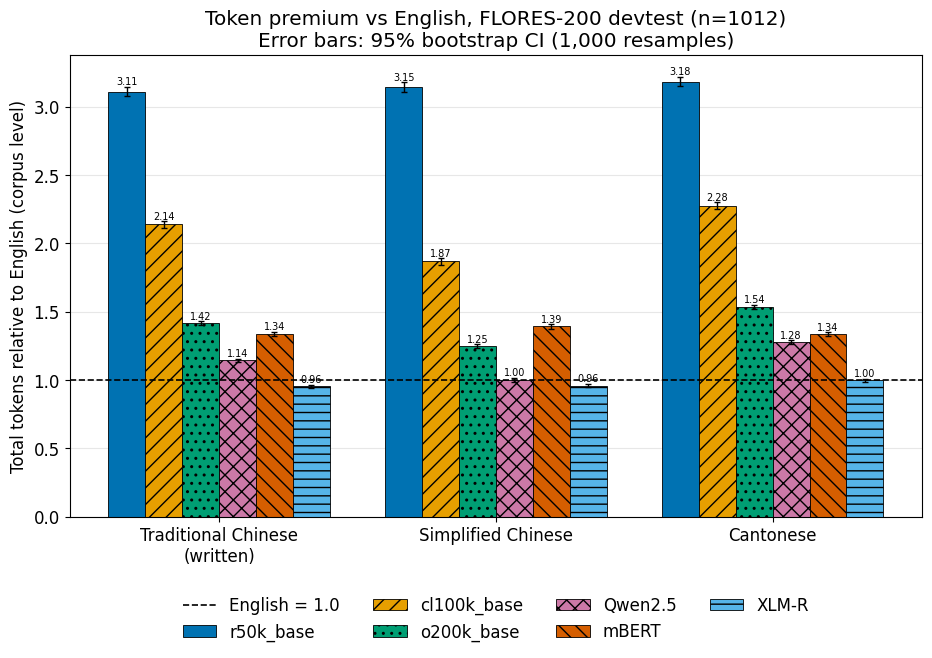

In [18]:
q = bs[bs.quantity.str.endswith("/ EN")].assign(category=lambda d: d.quantity.str.split(" / ").str[0])
lo, hi = (q.pivot(index="tokenizer", columns="category", values=c).loc[order, CATS[1:4]] for c in ("ci_low", "ci_high"))
grouped_bar(fp, "Total tokens relative to English (corpus level)",
            f"Token premium vs English, FLORES-200 devtest (n={len(ids)})\nError bars: 95% bootstrap CI ({N_BOOT:,} resamples)",
            OUT / "chart_flores_premium.png", ref=1.0, err=(lo, hi))

In [19]:
cmp = pd.DataFrame([dict(tokenizer=t, category=c, own_5set_premium=pr.loc[t, c], flores_premium=fp.loc[t, c])
                    for t in order for c in CATS[1:4]])
cmp["difference_flores_minus_own"] = cmp.flores_premium - cmp.own_5set_premium
cmp.round(4).to_csv(OUT / "flores_vs_own.csv", index=False, encoding="utf-8")
print("Premium vs English: own 5-set (mean of per-sentence ratios) vs FLORES (corpus level)")
cmp.round(2)

Premium vs English: own 5-set (mean of per-sentence ratios) vs FLORES (corpus level)


,tokenizer,category,own_5set_premium,flores_premium,difference_flores_minus_own
0,r50k_base,ZH_WRITTEN,2.65,3.11,0.47
1,r50k_base,ZH_SIMPLIFIED,2.66,3.15,0.49
2,r50k_base,CANTONESE,2.62,3.18,0.56
3,cl100k_base,ZH_WRITTEN,1.64,2.14,0.50
4,cl100k_base,ZH_SIMPLIFIED,1.29,1.87,0.57
5,cl100k_base,CANTONESE,1.69,2.28,0.58
6,o200k_base,ZH_WRITTEN,1.09,1.42,0.33
7,o200k_base,ZH_SIMPLIFIED,0.99,1.25,0.26
8,o200k_base,CANTONESE,1.36,1.54,0.18
9,Qwen2.5,ZH_WRITTEN,0.88,1.14,0.27


## 8. Charts (hand-written set)

Grouped bars: x-axis = language category, one bar per tokenizer (colours differ and bars are also hatched, so the print stays readable in greyscale). Both charts are saved at 300 dpi. The premium chart has no `EN` or `CODE` group (the baseline is English itself; code has no English counterpart). The tokens-per-character chart excludes `EN` but includes `CODE`.

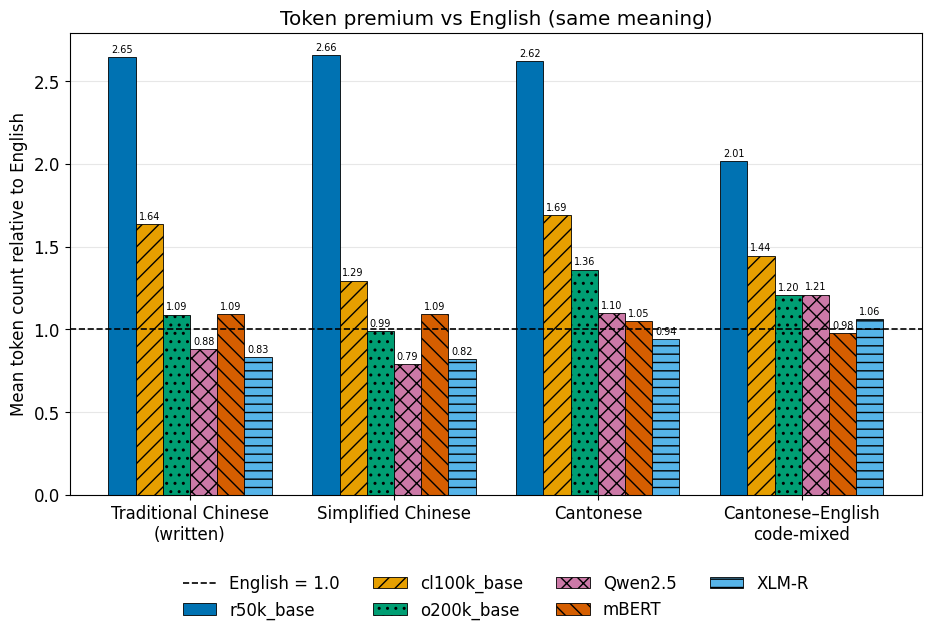

In [20]:
grouped_bar(pr, "Mean token count relative to English", "Token premium vs English (same meaning)",
            OUT / "chart_premium.png", ref=1.0)

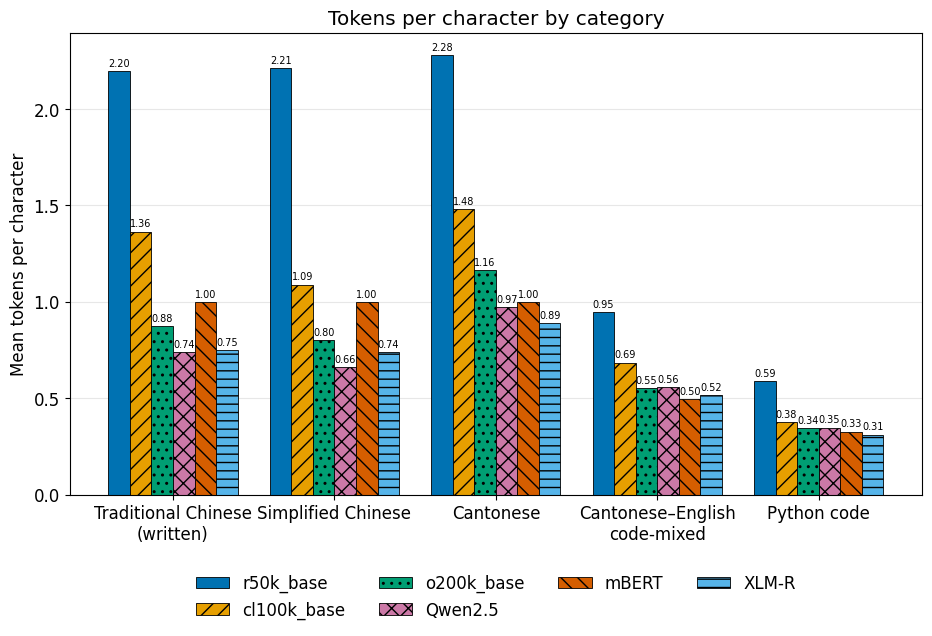

In [21]:
tpc = summary.pivot(index="tokenizer", columns="category", values="mean_tokens_per_char").loc[order, CATS[1:]]
grouped_bar(tpc, "Mean tokens per character", "Tokens per character by category",
            OUT / "chart_tokens_per_char.png")

## 9. Round-trip check

A lower token count is only meaningful if the text can be reconstructed from the tokens. For every tokenizer × sample we decode the ids and compare with the original at two levels:

- `roundtrip_exact`: `decoded == original`.
- `roundtrip_content`: equality after NFKC normalisation and removal of all whitespace (natural-language categories only).

Formatting differences, such as spaces inserted by the decoder or full-width punctuation turned into half-width (`，` → `,`), are **not** information loss. Characters replaced by `[UNK]` and dropped indentation or newlines in code **are**. The list of failing samples below lets you check which cause applies.

In [22]:
rt = (results.assign(roundtrip_exact=results.roundtrip_exact.astype(float))
      .pivot_table(index="tokenizer", columns="category", values="roundtrip_exact", aggfunc="mean")
      .loc[order, CATS])
print("Round-trip success rate (1.00 = every sample reconstructed exactly)")
display(rt.round(2))

Round-trip success rate (1.00 = every sample reconstructed exactly)


category,EN,ZH_WRITTEN,ZH_SIMPLIFIED,CANTONESE,CODE_MIXED,CODE
tokenizer,,,,,,
r50k_base,1.0,1.0,1.0,1.0,1.0,1.0
cl100k_base,1.0,1.0,1.0,1.0,1.0,1.0
o200k_base,1.0,1.0,1.0,1.0,1.0,1.0
Qwen2.5,1.0,1.0,1.0,1.0,1.0,1.0
mBERT,0.6,0.0,0.0,0.0,0.0,0.0
XLM-R,1.0,0.2,0.2,0.2,0.2,0.0


In [23]:
rc = (results[results.category != "CODE"].assign(roundtrip_content=lambda d: d.roundtrip_content.astype(float))
      .pivot_table(index="tokenizer", columns="category", values="roundtrip_content", aggfunc="mean")
      .reindex(index=order, columns=CATS))
print("Content round-trip success rate (NFKC + whitespace removed; CODE not applicable)")
display(rc.round(2).fillna("n/a"))

Content round-trip success rate (NFKC + whitespace removed; CODE not applicable)


category,EN,ZH_WRITTEN,ZH_SIMPLIFIED,CANTONESE,CODE_MIXED,CODE
tokenizer,,,,,,
r50k_base,1.0,1.0,1.0,1.0,1.0,n/a
cl100k_base,1.0,1.0,1.0,1.0,1.0,n/a
o200k_base,1.0,1.0,1.0,1.0,1.0,n/a
Qwen2.5,1.0,1.0,1.0,1.0,1.0,n/a
mBERT,1.0,1.0,1.0,0.0,0.2,n/a
XLM-R,1.0,1.0,1.0,1.0,1.0,n/a


In [24]:
bad = results[(results.roundtrip_content == False) | ((results.category == "CODE") & ~results.roundtrip_exact)]
bad = bad.assign(failed_check=bad.category.map(lambda c: "exact (CODE)" if c == "CODE" else "content"))
cols = ["tokenizer", "sample_id", "failed_check", "unk_count", "text", "decoded"]
print(f"{len(bad)} failing samples (original vs decoded)")
bad[cols].rename(columns={"text": "original"}).style.hide(axis="index").set_properties(
    **{"text-align": "left", "white-space": "pre-wrap"})

15 failing samples (original vs decoded)


tokenizer,sample_id,failed_check,unk_count,original,decoded
mBERT,set1_CANTONESE,content,1,我陣間同啲同事去食晏。,我 陣 間 同 [UNK] 同 事 去 食 晏 。
mBERT,set1_CODE_MIXED,content,1,我陣間同啲 colleague 去 lunch。,我 陣 間 同 [UNK] colleague 去 lunch 。
mBERT,set2_CANTONESE,content,1,個客唔得閒，所以個會改咗去下個禮拜一。,個 客 唔 得 閒 ， 所 以 個 會 改 [UNK] 去 下 個 禮 拜 一 。
mBERT,set2_CODE_MIXED,content,1,個 client 唔得閒，所以個 meeting postpone 咗去下個 Monday。,個 client 唔 得 閒 ， 所 以 個 meeting postpone [UNK] 去 下 個 Monday 。
mBERT,set3_CANTONESE,content,1,你可唔可以將份設計檔最新嗰個版本傳俾我？,你 可 唔 可 以 將 份 設 計 檔 最 新 [UNK] 個 版 本 傳 俾 我 ？
mBERT,set4_CANTONESE,content,1,呢個項目好趕，所以我哋要加班。,呢 個 項 目 好 趕 ， 所 以 我 [UNK] 要 加 班 。
mBERT,set4_CODE_MIXED,content,1,呢個 project 個 deadline 好 tight，所以我哋要 OT。,呢 個 project 個 deadline 好 tight ， 所 以 我 [UNK] 要 OT 。
mBERT,set5_CANTONESE,content,1,我好耐冇見過佢，唔知佢而家做緊乜嘢。,我 好 耐 冇 見 過 佢 ， 唔 知 佢 而 家 做 緊 [UNK] 嘢 。
mBERT,set5_CODE_MIXED,content,1,我好耐冇見過佢，唔知佢而家做緊乜 job。,我 好 耐 冇 見 過 佢 ， 唔 知 佢 而 家 做 緊 [UNK] job 。
mBERT,code_a,exact (CODE),0,"def add_tax(price, rate=0.05): tax = price * rate total = price + tax return round(total, 2)","def add _ tax ( price, rate = 0. 05 ) : tax = price * rate total = price + tax return round ( total, 2 )"


## 10. Token boundary visualisation

Set 2 in all five versions (EN, Traditional, Simplified, Cantonese, code-mixed) plus code snippet (a), segmented by every tokenizer. Hugging Face tokenizers use their offset mappings; for tiktoken each token's bytes are mapped back to the characters they cover. Characters split across several byte-level tokens are hatched and outlined; unknown tokens are red. The same view is saved as `output/token_boundaries.html`.

In [25]:
set2 = next(s for s in data["sets"] if s["id"] == 2)
items = [(f"Set 2 – {c}", set2[c]) for c in CATS[:5]]
items.append(("Code snippet (a)", next(c["text"] for c in data["code"] if c["id"] == "a")))
body = LEGEND + "".join(render_section(title, text, TOKS) for title, text in items)
page = ('<!doctype html><html lang="en"><head><meta charset="utf-8"><title>Token boundaries</title>'
        f'<style>{CSS}body{{margin:16px}}</style></head><body><div class="tbv">{body}</div></body></html>')
(OUT / "token_boundaries.html").write_text(page, encoding="utf-8")
display(HTML(f"<style>{CSS}</style><div class='tbv'>{body}</div>"))

## 11. Mitigation: removing spaces in code-mixed text

**Hypothesis.** In byte-level BPE, a space is usually merged into the *following* token (e.g. `·client`). A space in front of a CJK character produces a `space + character` byte sequence that is rarely a known token, so the pair may be split into several byte-level tokens (fragments). Removing the space between Chinese and English (`個 client 唔得閒` → `個client唔得閒`) might let the Chinese character be matched as an ordinary token. Spaces between two English words are kept.

**Trade-off.** People do not normally type code-mixed text without spaces, so this is an engineering mitigation (e.g. a pre-processing step), **not** a recommendation for users. It also changes the text, so token counts of the two versions describe different strings.

For each tokenizer and `CODE_MIXED` sentence we report the token count of both versions, the absolute and percentage change, and fragment and `[UNK]` counts. Rows with `scope = mean` (empty `set_id`) use the mean token counts over the five sentences (percentage = change of means / mean of originals). Results go to `output/mitigation.csv`.

In [26]:
mix = samples[samples.category == "CODE_MIXED"]
pd.DataFrame({"original": mix.text.values, "no_space": [strip_cjk_spaces(t) for t in mix.text]}, index=mix.set_id.values)

,original,no_space
1,我陣間同啲 colleague 去 lunch。,我陣間同啲colleague去lunch。
2,個 client 唔得閒，所以個 meeting postpone 咗去下個 Monday。,個client唔得閒，所以個meeting postpone咗去下個Monday。
3,你可唔可以 send 份 design file 嘅 latest version 俾我？,你可唔可以send份design file嘅latest version俾我？
4,呢個 project 個 deadline 好 tight，所以我哋要 OT。,呢個project個deadline好tight，所以我哋要OT。
5,我好耐冇見過佢，唔知佢而家做緊乜 job。,我好耐冇見過佢，唔知佢而家做緊乜job。


In [27]:
def compare(tok, r):
    a, b = r.text, strip_cjk_spaces(r.text)
    ma, mb = measure(tok, a, "CODE_MIXED"), measure(tok, b, "CODE_MIXED")
    return dict(tokenizer=tok.label, set_id=r.set_id, original=a, no_space=b,
                tokens_original=ma["token_count"], tokens_no_space=mb["token_count"],
                fragments_original=ma["fragment_count"], fragments_no_space=mb["fragment_count"],
                unk_original=ma["unk_count"], unk_no_space=mb["unk_count"])

def add_change(d):
    d["abs_change"] = d["tokens_no_space"] - d["tokens_original"]
    d["pct_change"] = 100 * d["abs_change"] / d["tokens_original"]
    return d

rows = []
for t in TOKS:
    part = pd.DataFrame([compare(t, r) for _, r in mix.iterrows()])
    avg = part.drop(columns=["original", "no_space", "set_id"]).groupby("tokenizer", as_index=False).mean()
    part["scope"], avg["scope"] = "sentence", "mean"
    rows += [add_change(part), add_change(avg)]
mit = pd.concat(rows, ignore_index=True).round(4)
mit["set_id"] = mit.set_id.astype("Int64")   # integer; empty in the "mean" rows
mit.insert(2, "scope", mit.pop("scope"))
mit.to_csv(OUT / "mitigation.csv", index=False, encoding="utf-8")
mit[mit.scope == "mean"].drop(columns=["original", "no_space", "set_id", "scope"]).set_index("tokenizer")

,tokens_original,tokens_no_space,fragments_original,fragments_no_space,unk_original,unk_no_space,abs_change,pct_change
tokenizer,,,,,,,,
r50k_base,30.0,30.0,25.6,25.2,0.0,0.0,0.0,0.0000
cl100k_base,21.6,20.4,11.8,10.2,0.0,0.0,-1.2,-5.5556
o200k_base,17.2,17.2,6.0,6.0,0.0,0.0,0.0,0.0000
Qwen2.5,17.8,15.8,5.6,2.8,0.0,0.0,-2.0,-11.2360
mBERT,15.8,15.8,0.0,0.0,0.8,0.8,0.0,0.0000
XLM-R,16.6,16.4,0.0,0.0,0.0,0.0,-0.2,-1.2048


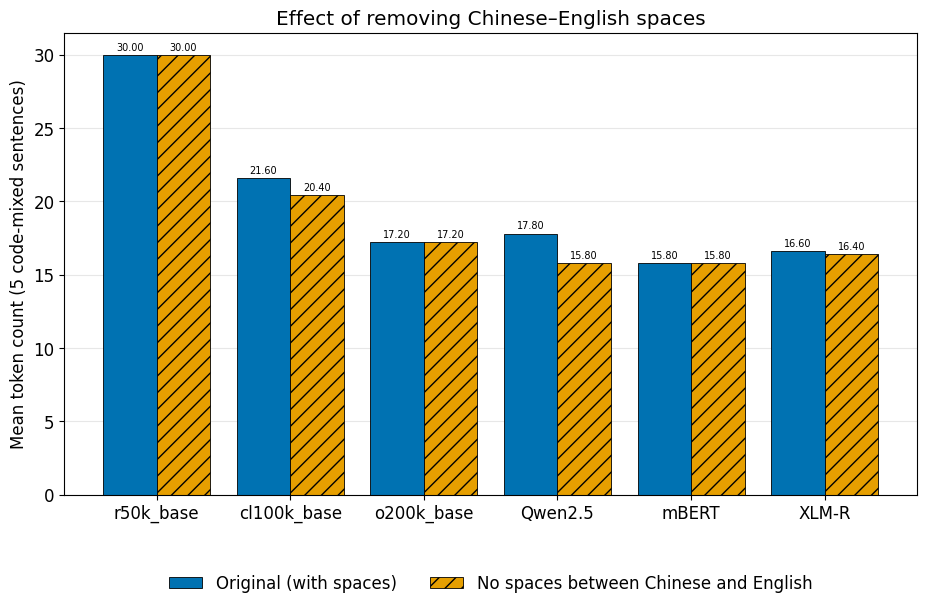

In [28]:
mean = mit[mit.scope == "mean"].set_index("tokenizer").loc[order]
tbl = pd.DataFrame({"Original (with spaces)": mean.tokens_original,
                    "No spaces between Chinese and English": mean.tokens_no_space}).T
grouped_bar(tbl, "Mean token count (5 code-mixed sentences)", "Effect of removing Chinese–English spaces",
            OUT / "chart_mitigation.png")

In [ ]:
s2 = next(s for s in data["sets"] if s["id"] == 2)["CODE_MIXED"]
pair = [("Set 2 – CODE_MIXED (original)", s2), ("Set 2 – CODE_MIXED (Chinese–English spaces removed)", strip_cjk_spaces(s2))]
body2 = LEGEND + "".join(render_section(title, text, TOKS) for title, text in pair)
page2 = ('<!doctype html><html lang="en"><head><meta charset="utf-8"><title>Mitigation token boundaries</title>'
         f'<style>{CSS}body{{margin:16px}}</style></head><body><div class="tbv">{body2}</div></body></html>')
(OUT / "token_boundaries_mitigation.html").write_text(page2, encoding="utf-8")
display(HTML(f"<style>{CSS}</style><div class='tbv'>{body2}</div>"))

## 12. Vocabulary extension demo (mBERT)

mBERT maps some Cantonese characters to `[UNK]`. This section (1) finds those characters automatically in the test set, (2) adds them to a **fresh copy** of the tokenizer with `add_tokens()` and re-measures the Cantonese and code-mixed samples, and (3) reads only `config.json` (no model weights) to count how many new embedding parameters the extension would require: `new tokens × hidden_size`.

Notes:
- **(a) Representation only.** Adding tokens fixes the *tokenizer*. The new embedding rows would be randomly initialised, so the model cannot use them until it is fine-tuned or further pre-trained.
- **(b) Same mechanism at scale.** Large-scale vocabulary extension for Chinese works the same way: add tokens, resize the embedding matrix, continue training.
- **(c) Byte-level BPE avoids `[UNK]` by design.** Any string can be represented as bytes, which the round-trip results above already show: r50k, cl100k, o200k and Qwen2.5 have no `[UNK]` and reconstruct every sample.

In [30]:
mb = next(t for t in TOKS if t.label == "mBERT")
unk_id = mb.tok.unk_token_id

def unk_chars(text):
    # characters inside [UNK] spans that are also [UNK] on their own
    found = set()
    for p in mb.analyze(text):
        if p["unk"]:
            found |= {c for c in p["span"] if not c.isspace()}
    return {c for c in found if mb.tok(c, add_special_tokens=False)["input_ids"] == [unk_id]}

chars = sorted(set().union(*(unk_chars(t) for t in samples.text)))
unk_table = pd.DataFrame([dict(char=c, codepoint=f"U+{ord(c):04X}", occurrences=int(samples.text.str.count(c).sum()),
                               samples=", ".join(samples.sample_id[samples.text.str.contains(c)])) for c in chars])
unk_table = unk_table.sort_values(["occurrences", "char"], ascending=[False, True]).reset_index(drop=True)
unk_table

,char,codepoint,occurrences,samples
0,乜,U+4E5C,2,"set5_CANTONESE, set5_CODE_MIXED"
1,咗,U+5497,2,"set2_CANTONESE, set2_CODE_MIXED"
2,哋,U+54CB,2,"set4_CANTONESE, set4_CODE_MIXED"
3,啲,U+5572,2,"set1_CANTONESE, set1_CODE_MIXED"
4,嗰,U+55F0,1,set3_CANTONESE


In [31]:
ext = HFTok("bert-base-multilingual-cased", "mBERT+ext", "mBERT with added tokens")   # fresh copy
n_before = len(ext.tok)
added = ext.tok.add_tokens(list(unk_table.char))
ext.vocab_size = len(ext.tok)
assert added == len(unk_table) and len(mb.tok) == n_before, "original tokenizer must stay unchanged"
print(f"added {added} tokens: vocabulary {n_before} -> {len(ext.tok)}")

added 5 tokens: vocabulary 119547 -> 119552


In [32]:
sub = samples[samples.category.isin(["CANTONESE", "CODE_MIXED"])]
rows = []
for _, r in sub.iterrows():
    b, a = measure(mb, r.text, r.category), measure(ext, r.text, r.category)
    rows.append(dict(sample_id=r.sample_id, category=r.category,
                     token_count_before=b["token_count"], token_count_after=a["token_count"],
                     unk_before=b["unk_count"], unk_after=a["unk_count"],
                     roundtrip_content_before=b["roundtrip_content"], roundtrip_content_after=a["roundtrip_content"]))
vext = pd.DataFrame(rows)
vext.to_csv(OUT / "vocab_extension.csv", index=False, encoding="utf-8")
vext

,sample_id,category,token_count_before,token_count_after,unk_before,unk_after,roundtrip_content_before,roundtrip_content_after
0,set1_CANTONESE,CANTONESE,11,11,1,0,False,True
1,set1_CODE_MIXED,CODE_MIXED,11,11,1,0,False,True
2,set2_CANTONESE,CANTONESE,19,19,1,0,False,True
3,set2_CODE_MIXED,CODE_MIXED,18,18,1,0,False,True
4,set3_CANTONESE,CANTONESE,20,20,1,0,False,True
5,set3_CODE_MIXED,CODE_MIXED,15,15,0,0,True,True
6,set4_CANTONESE,CANTONESE,15,15,1,0,False,True
7,set4_CODE_MIXED,CODE_MIXED,17,17,1,0,False,True
8,set5_CANTONESE,CANTONESE,18,18,1,0,False,True
9,set5_CODE_MIXED,CODE_MIXED,18,18,1,0,False,True


In [33]:
from transformers import AutoConfig
cfg = AutoConfig.from_pretrained("bert-base-multilingual-cased")   # downloads config.json only
n_new = len(ext.tok) - len(mb.tok)
pd.Series({"hidden_size": cfg.hidden_size, "original vocab size": len(mb.tok), "new vocab size": len(ext.tok),
           "new tokens": n_new, "new embedding parameters (new tokens x hidden_size)": n_new * cfg.hidden_size},
          name="value").to_frame()

,value
hidden_size,768
original vocab size,119547
new vocab size,119552
new tokens,5
new embedding parameters (new tokens x hidden_size),3840
